# 📘 Notebook 04: Adult Census Income, Who Earns More, and Is the Model Fair?

### Course: *From Questions to Answers: Classic Datasets, Fully Explored*
**Instructor:** Ioannis Tsioulis

*Dataset 4 · 1994 US Census extract (32,561 adults, 15 columns)*

---

> 💡 **This notebook is already run.** Every table and chart below was produced by the code above it, and each result is followed by a comment that explains what it shows. You can read it without running anything. To experiment, choose **Runtime → Run all** in Colab; the whole notebook runs in about a minute. If you rerun it, numbers from the models may differ slightly in the last decimal, because Colab may have newer library versions.

## 🎯 Learning objectives

By the end of this notebook you will be able to:

- Find missing values that are **disguised** as ordinary symbols
- Spot **duplicate columns** that say the same thing in two ways
- Explain why **accuracy misleads** when the classes are unbalanced, and use **precision** and **recall** instead
- Move a model's **decision threshold** to trade one kind of error for another
- Measure whether a model treats **two groups** differently
- Explain why **deleting a sensitive column does not make a model fair**

> **Prerequisites:** [Notebook 01: Titanic](https://colab.research.google.com/github/giannis00/giannis00.github.io/blob/main/assets/jupyter/from-questions-to-answers/01_titanic.ipynb).
>
> 🔭 **Why this notebook matters:** models now help decide who gets a loan, a job interview or an insurance price. These decisions are made from data about people, and that data carries the inequalities of the society it came from. This dataset, extracted from the 1994 US Census by Ronny Kohavi and Barry Becker, is the standard first case study in **fairness**: a small, real example of how a model can repeat a pattern that nobody intended it to learn.

## 0. The question

For each adult we know age, education, job, marital status, sex, race, working hours and investment income, and whether they earned **more than 50,000 dollars a year** (in 1994 dollars).

**Our question:** *Who earns more than 50,000 dollars, and would a model that predicts it treat women and men fairly?* More precisely:

1. Which characteristics go with a high income?
2. How should we judge a model when only a quarter of the people are in the class we care about?
3. Does the model make different mistakes for women and for men, and can we fix that by hiding the `sex` column?

In [1]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.precision", 3)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 80

## 1. Loading the data from a URL

The file comes from the UCI Machine Learning Repository. It has **no header row**, so we supply the column names, and it writes a space after every comma, which `skipinitialspace=True` removes.

In [2]:
URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data"
columns = ["age", "workclass", "fnlwgt", "education", "education_num", "marital_status", "occupation",
           "relationship", "race", "sex", "capital_gain", "capital_loss", "hours_per_week", "native_country", "income"]
raw = pd.read_csv(URL, names=columns, skipinitialspace=True)
print(raw.shape)
raw.head()

(32561, 15)


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


**What we see.** 32,561 adults and 15 columns. Most are categories. `fnlwgt` ("final weight") is the number of people in the population that each row stands for, a survey weight that we will not use as a feature. `income` is the answer: `<=50K` or `>50K`.

## 2. Disguised missing values and duplicate columns

In [3]:
print("Missing values reported by pandas:", raw.isna().sum().sum())
for col in ["workclass", "occupation", "native_country"]:
    print(f"{col:15s} rows equal to '?':", (raw[col] == "?").sum())

Missing values reported by pandas: 0
workclass       rows equal to '?': 1836
occupation      rows equal to '?': 1843
native_country  rows equal to '?': 583


**What we see.** pandas reports **zero** missing values, yet three columns contain the symbol **`?`**: 1,836 in `workclass`, 1,843 in `occupation` and 583 in `native_country`. The data **is** incomplete; it simply marks gaps with a question mark instead of leaving them empty. Checking `isna()` alone would have hidden this.

We reload the file telling pandas that `?` means missing.

In [4]:
df = pd.read_csv(URL, names=columns, skipinitialspace=True, na_values="?")
df["high_income"] = (df["income"] == ">50K").astype(int)
print(df.isna().sum()[lambda s: s > 0])
print("Duplicate rows:", df.duplicated().sum())

workclass         1836
occupation        1843
native_country     583
dtype: int64
Duplicate rows: 24


In [5]:
pd.crosstab(df["education"], df["education_num"]).iloc[:6, :8]

education_num,1,2,3,4,5,6,7,8
education,,,,,,,,
10th,0,0,0,0,0,933,0,0
11th,0,0,0,0,0,0,1175,0
12th,0,0,0,0,0,0,0,433
1st-4th,0,168,0,0,0,0,0,0
5th-6th,0,0,333,0,0,0,0,0
7th-8th,0,0,0,646,0,0,0,0


**What we see.** Every `education` value matches exactly **one** `education_num` value: `education_num` is simply the education level as a number from 1 (preschool) to 16 (doctorate). Two columns, one piece of information. We keep the number, which has a natural order, and drop the text.

There are also 24 duplicate rows. With people described by a dozen broad categories, two different people can easily share every value, so here duplicates are plausible and we keep them. In a dataset with names or IDs, duplicates would be a red flag.

**Decision for the gaps:** we drop the rows with any `?`. That removes 7% of the data. A careful analyst would first check that the dropped rows are not very different from the rest (Exercise 1 asks you to).

In [6]:
df = df.dropna().drop(columns=["education", "fnlwgt"]).reset_index(drop=True)
print(len(df), "complete rows")
print("Share earning more than 50K:", round(df["high_income"].mean(), 3))

30162 complete rows
Share earning more than 50K: 0.249


**What we see.** 30,162 complete rows, of which only **24.9%** earn more than 50,000 dollars. The classes are **unbalanced**: three people out of four are in the "no" class. Keep this number in mind; it will change how we judge models.

## 3. Who earns more?

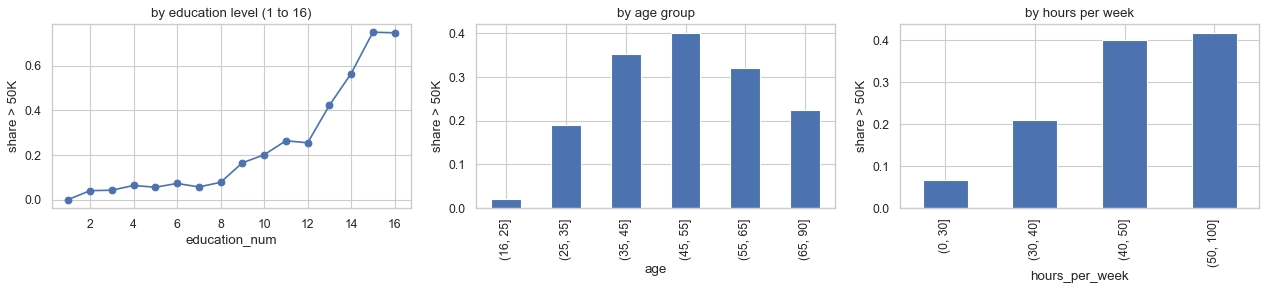

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
df.groupby("education_num")["high_income"].mean().plot(marker="o", ax=axes[0], title="by education level (1 to 16)")
df.groupby(pd.cut(df["age"], [16, 25, 35, 45, 55, 65, 90]))["high_income"].mean().plot.bar(ax=axes[1], title="by age group")
df.groupby(pd.cut(df["hours_per_week"], [0, 30, 40, 50, 100]))["high_income"].mean().plot.bar(ax=axes[2], title="by hours per week")
for ax in axes:
    ax.set_ylabel("share > 50K")
plt.tight_layout()
plt.show()

**What we see.**
- **Education:** the share rises steadily with each level and jumps at the top: about 42% for a bachelor's degree and 75% for professional degrees and doctorates.
- **Age:** a hill, not a line. Almost nobody under 25 earns over 50K (about 2%), the share peaks at **45 to 55** (about 40%) and falls after 55.
- **Hours:** part-time workers rarely do; above 40 hours a week, about 40% do.

In [8]:
df.groupby("marital_status")["high_income"].agg(share="mean", people="size").sort_values("share", ascending=False)

,share,people
marital_status,,
Married-AF-spouse,0.476,21
Married-civ-spouse,0.455,14065
Divorced,0.107,4214
Widowed,0.097,827
Married-spouse-absent,0.084,370
Separated,0.070,939
Never-married,0.048,9726


**What we see.** The strongest single split in the data is **marital status**: about **45%** of married people (living with their spouse) earn over 50K, against less than **5%** of the never married. Marriage does not raise a salary by itself; it goes with **age** (married people are older) and, in 1994, with the household's main earner answering the census. This is another reminder that a strong pattern is not a cause.

In [9]:
df.groupby("sex")["high_income"].agg(share="mean", people="size")

,share,people
sex,,
Female,0.114,9782
Male,0.314,20380


In [10]:
pd.crosstab(df["relationship"], df["sex"])

sex,Female,Male
relationship,,
Husband,1,12462
Not-in-family,3566,4160
Other-relative,386,503
Own-child,1961,2505
Unmarried,2463,749
Wife,1405,1


**What we see.** **31%** of men earn over 50K, against **11%** of women, a ratio of almost three to one. And look at the `relationship` column: **every** "Husband" is male and **every** "Wife" female, except a few data entry errors. The column **is** the sex column for married people. Remember this; it will matter in Section 6.

In [11]:
by_sex = df.groupby("sex")
print(by_sex["hours_per_week"].mean().round(1))
by_sex["occupation"].value_counts(normalize=True).unstack(0).round(2).sort_values("Female", ascending=False).head(6)

sex
Female    36.9
Male      42.9
Name: hours_per_week, dtype: float64


sex,Female,Male
occupation,,
Adm-clerical,0.26,0.06
Other-service,0.18,0.07
Prof-specialty,0.15,0.12
Sales,0.13,0.11
Exec-managerial,0.12,0.14
Machine-op-inspct,0.06,0.07


**What we see.** Part of the gap is explained by other columns: women in this data work fewer paid hours on average (about **37** a week against **43**), and are concentrated in different occupations (adm-clerical and "other service" far more than men; craft-repair and transport far less). These differences are themselves part of the inequality the data records. A model trained on this data will see all of them.

## 4. Investment income: a zero-inflated column

In [12]:
print("Share with capital_gain = 0:", round((df["capital_gain"] == 0).mean(), 3))
print("Largest value:", df["capital_gain"].max(), " people with exactly 99999:", (df["capital_gain"] == 99999).sum())

Share with capital_gain = 0: 0.916
Largest value: 99999  people with exactly 99999: 148


**What we see.** About **92%** of people have **zero** capital gains, and among the rest there is a cluster at exactly **99,999**: the census capped large values at that number. A column like this, mostly zero with a few huge values, is called **zero-inflated**. Its mean and standard deviation describe nobody. For EDA, it is more honest to describe it as two questions: *did the person have any capital gain?* and *if so, how much?*

## 5. Judging a model when classes are unbalanced

### Intuition first
A model that says "no" to everybody is right **75%** of the time and useless. With unbalanced classes we ask two sharper questions about the people who **really** earn over 50K, the positive class:
- **Recall:** of the people who really earn over 50K, what share did the model find?
- **Precision:** of the people the model **said** earn over 50K, what share really do?

We split the data once into a training set (70%) and a test set (30%) and keep the test set aside, because in Section 6 we will look at the test predictions group by group.

In [13]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix, roc_auc_score

features = ["age", "workclass", "education_num", "marital_status", "occupation", "relationship",
            "race", "sex", "capital_gain", "capital_loss", "hours_per_week"]
X = pd.get_dummies(df[features], drop_first=True)
y = df["high_income"]
X_train, X_test, y_train, y_test, sex_train, sex_test = train_test_split(
    X, y, df["sex"], test_size=0.3, random_state=42, stratify=y)

logreg = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)).fit(X_train, y_train)
pred = logreg.predict(X_test)
proba = logreg.predict_proba(X_test)[:, 1]

print(f"Baseline 'always no':  accuracy {1 - y_test.mean():.3f}, recall 0.000")
print(f"Logistic regression:   accuracy {accuracy_score(y_test, pred):.3f}, recall {recall_score(y_test, pred):.3f}, precision {precision_score(y_test, pred):.3f}")
pd.DataFrame(confusion_matrix(y_test, pred), index=["really <=50K", "really >50K"], columns=["predicted <=50K", "predicted >50K"])

Baseline 'always no':  accuracy 0.751, recall 0.000
Logistic regression:   accuracy 0.847, recall 0.610, precision 0.729


,predicted <=50K,predicted >50K
really <=50K,6286,511
really >50K,878,1374


**What we see.** Accuracy is **84.7%**, which sounds excellent, until we remember that "always no" already scores **75.1%**. The confusion matrix shows the rest of the story: of the 2,252 people in the test set who really earn over 50K, the model finds **1,374**, a recall of **61.0%**, and misses **878**. When it says ">50K" it is right **72.9%** of the time.

Whether that is good depends on the use. A bank looking for wealthy customers to call may accept many false alarms to miss fewer; an automated decision that harms people when wrong may want the opposite.

In [14]:
for threshold in [0.3, 0.5]:
    p = (proba > threshold).astype(int)
    print(f"threshold {threshold}: accuracy {accuracy_score(y_test, p):.3f}, recall {recall_score(y_test, p):.3f}, precision {precision_score(y_test, p):.3f}")

threshold 0.3: accuracy 0.822, recall 0.789, precision 0.610
threshold 0.5: accuracy 0.847, recall 0.610, precision 0.729


**What we see.** A model outputs a **probability**, and "predict >50K" means "probability above 0.5" only by default. Lowering the threshold to **0.3** raises recall from **61%** to **79%** at the cost of precision (from **73%** to **61%**) and a little accuracy. The threshold is a **decision**, not a technical detail: it should be set by the cost of each kind of mistake.

In [15]:
boost = HistGradientBoostingClassifier(random_state=42).fit(X_train, y_train)
pred_boost = boost.predict(X_test)
print(f"Gradient boosting: accuracy {accuracy_score(y_test, pred_boost):.3f}, recall {recall_score(y_test, pred_boost):.3f}, "
      f"AUC {roc_auc_score(y_test, boost.predict_proba(X_test)[:, 1]):.3f} (logistic regression AUC {roc_auc_score(y_test, proba):.3f})")

Gradient boosting: accuracy 0.866, recall 0.659, AUC 0.922 (logistic regression AUC 0.902)


**What we see.** A gradient boosting model, one of the strongest methods for tables, does somewhat better: accuracy **86.6%**, recall **65.9%**. The **AUC** (area under the ROC curve) summarises how well a model ranks people by probability over **all** thresholds: 1 is perfect, 0.5 is a coin. Boosting reaches **0.922** against **0.902** for logistic regression. A real improvement, but a modest one compared with the effect of choosing the threshold.

## 6. Is the model fair to women and men?

### Intuition first
"Fair" has several precise meanings, and they can conflict. Two simple checks:
1. **How often** does the model predict ">50K" for each group, compared with how often it is true?
2. **Recall per group:** of the people in each group who really earn over 50K, what share does the model find?

In [16]:
def by_group(predictions):
    rows = {}
    for group in ["Female", "Male"]:
        k = (sex_test == group).values
        rows[group] = {"really >50K": y_test[k].mean(), "predicted >50K": predictions[k].mean(),
                       "recall": recall_score(y_test[k], predictions[k]), "precision": precision_score(y_test[k], predictions[k])}
    return pd.DataFrame(rows).T.round(3)

by_group(pred)

,really >50K,predicted >50K,recall,precision
Female,0.119,0.088,0.527,0.712
Male,0.310,0.265,0.625,0.732


**What we see.**
- Among women in the test set, **11.9%** really earn over 50K, and the model predicts it for **8.8%**. Among men, **31.0%** really do and the model predicts **26.5%**. The model **under-predicts** for both, but more for women.
- **Recall** is **52.7%** for women against **62.5%** for men: a woman who really earns over 50K is **less likely to be recognised** by the model than a man who does.
- Precision is about the same for both (**71%** and **73%**).

So the model does not only reflect the 3-to-1 gap in the data; it makes its mistakes unevenly. If such a model were used to offer, say, a premium financial product, qualified women would be overlooked more often than qualified men.

### Does deleting the `sex` column fix it?

In [17]:
no_sex = [c for c in X.columns if not c.startswith("sex_")]
blind = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)).fit(X_train[no_sex], y_train)
pred_blind = blind.predict(X_test[no_sex])
print("Accuracy without the sex column:", round(accuracy_score(y_test, pred_blind), 3))
by_group(pred_blind)

Accuracy without the sex column: 0.846


,really >50K,predicted >50K,recall,precision
Female,0.119,0.090,0.536,0.713
Male,0.310,0.261,0.618,0.734


**What we see.** Almost **nothing** changes. Without the `sex` column the model still predicts >50K for about **9%** of women and **26%** of men, and accuracy is the same. The reason is in Section 3: `relationship` says "Husband" or "Wife", and occupation and hours differ by sex. The information about sex is still there, spread over other columns, and the model finds it.

This is called **fairness through unawareness**, and it does not work. Deleting a sensitive column hides the problem from the people who read the code, not from the model. Real remedies measure fairness explicitly per group and correct for it, for example by choosing a different threshold per group or by training with fairness constraints; libraries such as *Fairlearn* exist for this. The first, essential step is the one we did: **measure every model separately for each group**.

## 7. Answer to the question

*Who earns more than 50,000 dollars, and would a model be fair?*

1. **Education, age (a hill peaking at 45 to 55), working hours and marriage** go with a high income; marital status is the strongest single split, mostly because it goes with age.
2. **Men are almost three times as likely** to earn over 50K in this 1994 data (31% against 11%), partly through hours and occupation.
3. With **unbalanced classes**, accuracy hides a lot: a model at 85% accuracy finds only 61% of the high earners, and moving the threshold trades recall for precision.
4. The model **recognises high-earning women less often** than high-earning men (recall 53% against 63%).
5. **Removing the `sex` column does not change this**, because `relationship`, occupation and hours carry the same information. Fairness must be measured per group, not assumed.

## 🚀 Going further (for experienced students)

### Equal opportunity with one threshold per group
Section 6 showed that deleting the `sex` column does not help. One documented remedy (Hardt, Price and Srebro, [*Equality of Opportunity in Supervised Learning*](https://arxiv.org/abs/1610.02413), 2016) keeps the model and chooses a **separate threshold for each group**, so that the **recall** is the same for women and men: a qualified person has the same chance of being recognised whatever their group. The library *Fairlearn* implements this as `ThresholdOptimizer`; here we do it by hand to see exactly what happens.

In [18]:
target_recall = recall_score(y_test, pred)
thresholds = {}
for group in ["Female", "Male"]:
    k = (sex_test == group).values
    scores_g = np.sort(proba[k][y_test.values[k] == 1])[::-1]
    thresholds[group] = scores_g[int(np.ceil(target_recall * len(scores_g))) - 1]
fair = np.zeros(len(proba), dtype=int)
for group, t in thresholds.items():
    k = (sex_test == group).values
    fair[k] = (proba[k] >= t).astype(int)
print("thresholds:", {g: round(float(t), 3) for g, t in thresholds.items()})
print("accuracy:", round(accuracy_score(y_test, fair), 3), "(single threshold:", round(accuracy_score(y_test, pred), 3), ")")
by_group(fair)

thresholds: {'Female': 0.36, 'Male': 0.513}
accuracy: 0.844 (single threshold: 0.847 )


,really >50K,predicted >50K,recall,precision
Female,0.119,0.115,0.611,0.637
Male,0.310,0.257,0.610,0.736


**What we see.** The threshold for women drops to **0.36** and for men rises to **0.51**. Recall becomes **61%** for both groups: a high-earning woman is now exactly as likely to be recognised as a high-earning man. The cost is small: accuracy falls from **84.7%** to **84.4%**, and precision for women falls to **64%** (more false alarms among women). This is the general pattern of fairness work: a chosen definition of fairness can usually be met, at a measurable price, and choosing the definition is a decision for people, not for the algorithm.

## ⚠️ Common pitfalls

- **Trusting `isna()`.** Missing values hide as `?`, `-1`, `999`, `"unknown"` or empty strings. Look at the values themselves.
- **Reporting accuracy alone on unbalanced classes.** Always compare with "always predict the majority", and report recall and precision for the class you care about.
- **Treating 0.5 as the only threshold.** The threshold is a business or ethical decision.
- **Reading a pattern as a cause.** Marriage does not double a salary; it goes with age.
- **Assuming that removing a sensitive column makes a model fair.** Other columns act as **proxies**. Measure outcomes per group.
- **Forgetting when and where the data comes from.** These are 1994 American incomes and 1994 social patterns; a model trained on them describes that world.

## ✏️ Exercises

### Exercise 1 (Were the dropped rows different?)
Reload the data with `na_values="?"` and compare the share earning over 50K among rows **with** a missing value and rows **without**. Was dropping them harmless?

In [19]:
# Your solution here:

<details><summary>💡 Show solution</summary>

```python
full = pd.read_csv(URL, names=columns, skipinitialspace=True, na_values="?")
full["high_income"] = (full["income"] == ">50K").astype(int)
has_gap = full.isna().any(axis=1)
print(full.groupby(has_gap)["high_income"].agg(["mean", "size"]).round(3))
```

*The rows with gaps earn over 50K noticeably less often than the complete rows: many of them have no `workclass` or `occupation` because they were not working. Dropping them makes the remaining data a little richer than the population. It is a small effect here, but it is exactly the kind of check that should come before any decision to drop rows.*
</details>

### Exercise 2 (The best threshold for a cost)
Suppose missing a real high earner costs **3** units and a false alarm costs **1**. Try thresholds from 0.1 to 0.9 on the logistic regression probabilities and find the one with the lowest total cost.

In [20]:
# Your solution here:

<details><summary>💡 Show solution</summary>

```python
costs = {}
for t in np.arange(0.1, 0.91, 0.05):
    p = (proba > t).astype(int)
    missed = ((p == 0) & (y_test == 1)).sum()
    false_alarms = ((p == 1) & (y_test == 0)).sum()
    costs[round(t, 2)] = 3 * missed + false_alarms
best = min(costs, key=costs.get)
print("best threshold:", best, " cost:", costs[best], "  cost at 0.5:", costs[0.5])
```

*When a miss costs three times a false alarm, the best threshold is well below 0.5. Choosing the threshold from the costs of the decision is how a model becomes a tool instead of a score.*
</details>

### Exercise 3 (A proxy hunt)
Train a logistic regression that predicts **sex** from all the other features (without income). If it is very accurate, the other columns are good proxies for sex. Which features does it rely on most?

In [21]:
# Your solution here:

<details><summary>💡 Show solution</summary>

```python
target = (df["sex"] == "Male").astype(int)
Xp = pd.get_dummies(df[[f for f in features if f != "sex"]], drop_first=True)
proxy = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000))
from sklearn.model_selection import cross_val_score
print("accuracy predicting sex:", round(cross_val_score(proxy, Xp, target, cv=5).mean(), 3),
      " baseline:", round(target.mean(), 3))
coefs = pd.Series(proxy.fit(Xp, target)[-1].coef_[0], index=Xp.columns)
print(coefs.abs().sort_values(ascending=False).head(6).round(2))
```

*Sex can be predicted far above the baseline, mostly from the `relationship` categories, followed by occupation and hours. Any column that can predict a sensitive attribute this well can carry its effect into a model.*
</details>

## 🔑 Key takeaways

- Missing values can be **disguised**; check the actual values, not only `isna()`.
- Look for **duplicate columns** that encode the same information.
- With **unbalanced classes**, compare with the majority baseline and report **recall** and **precision**.
- The **threshold** turns probabilities into decisions and should follow the costs of mistakes.
- Evaluate every model **separately per group** of people it affects.
- **Removing a sensitive column does not remove its information**: other columns act as proxies.

---
**Next:** *Notebook 05: Heart Disease*, where the data is medical, every column has a clinical meaning, and a missed diagnosis costs far more than a false alarm.

---
*© Ioannis Tsioulis. *From Questions to Answers: Classic Datasets, Fully Explored*. Prepared for educational use.*